<a href="https://colab.research.google.com/github/boradenihal15-beep/Deep-learning/blob/main/exp7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Model,Sequential
from tensorflow.keras.layers import Input,Dense
from tensorflow.keras.datasets import mnist
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 6ms/step - loss: 0.0290
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0169
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0150
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0140
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0133
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0129
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 8s 4ms/step - loss: 0.0126
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0123
Epoch 9/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 9s 5ms/step - loss: 0.0120
Epoch 10/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 0.0118
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


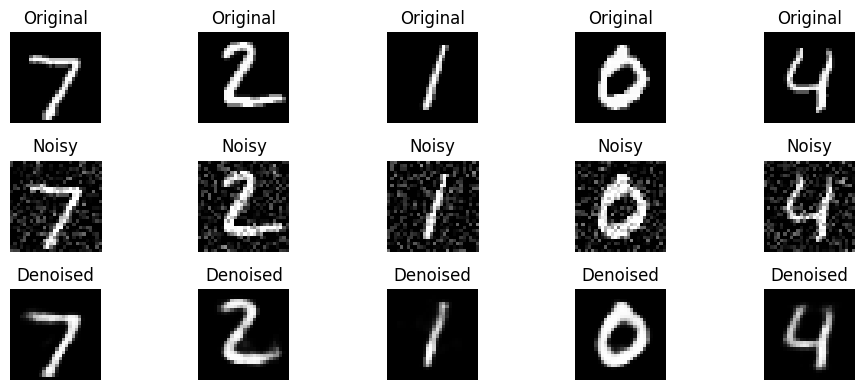

In [8]:
x,y=make_classification(
 n_samples=500,
 n_features=784,
 n_classes=2,
 random_state=42
)

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.1,random_state=42)

(x_train, _),(x_test, _)=mnist.load_data()

x_train=x_train.reshape(-1,784)/255.0
x_test=x_test.reshape(-1,784)/255.0

noise=np.random.normal(
    0,0.2,x_train.shape
)
x_train_noisy=np.clip(
    x_train+noise,0,1
)

input_img = Input(shape=(784,))

encoded = Dense(128, activation='relu')(input_img)
encoded = Dense(32, activation='relu')(encoded)

decoded = Dense(128, activation='relu')(encoded)
decoded = Dense(784, activation='sigmoid')(decoded)

autoencoder = Model(input_img, decoded)

autoencoder.compile(optimizer='adam',loss='mse')

autoencoder.fit(x_train_noisy,x_train,epochs=10)

noise_test = np.random.normal(0, 0.2, x_test.shape)

x_test_noisy = np.clip(
    x_test + noise_test, 0, 1
)

reconstructed = autoencoder.predict(x_test_noisy)

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))

for i in range(5):
    # Original image
    plt.subplot(3, 5, i+1)
    plt.imshow(x_test[i].reshape(28, 28), cmap='gray')
    plt.title("Original")
    plt.axis('off')

    # Noisy image
    plt.subplot(3, 5, i+6)
    plt.imshow(x_test_noisy[i].reshape(28, 28), cmap='gray')
    plt.title("Noisy")
    plt.axis('off')

    # Denoised image
    plt.subplot(3, 5, i+11)
    plt.imshow(reconstructed[i].reshape(28, 28), cmap='gray')
    plt.title("Denoised")
    plt.axis('off')

plt.tight_layout()
plt.show()